# DisMS-TS: Disentangled Multi-Scale Time Series Classification

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/disms_ts_classification.ipynb)

**Paper**: Zhipeng Liu, Peibo Duan, Binwu Wang, Xuan Tang, Qi Chu, Changsheng Zhang, Yongsheng Huang, Bin Zhang.
*DisMS-TS: Eliminating Redundant Multi-Scale Features for Time Series Classification*.
**ACM Multimedia (MM) 2025**. [arXiv:2507.04600](https://arxiv.org/abs/2507.04600) · DOI [10.1145/3746027.3754842](https://doi.org/10.1145/3746027.3754842)

**Official code**: [github.com/ZhipengLiu75/DisMS-TS](https://github.com/ZhipengLiu75/DisMS-TS)

Unlike the forecasting notebooks in this repo, DisMS-TS is a **classification** model, so this notebook uses the paper's own
UEA datasets and metrics (ACC, macro-F1, MCC) instead of the ETTh1 96→96 benchmark.

**Key ideas**
- **Multi-scale generation (MSG)**: the input series is repeatedly average-pooled to get $S+1$ views (fine to coarse).
- **Multi-scale temporal encoder (MTE)**: a per-variable 1-D convolution (*local multi-channel projection*) followed by a GRU (*global temporal aggregation*) with a learnable per-variable weight $\boldsymbol\beta$.
- **Temporal disentanglement module (TDM)**: a learned soft mask splits each scale's representation $\mathbf F_s$ into a **scale-shared** part $\mathbf F_{s,sha}$ and a **scale-specific** part $\mathbf F_{s,spe}$.
- **Two regularisers**: a *similarity* loss pushes the shared parts of all scales to agree, and a *disparity* loss pushes the specific parts of different scales to be orthogonal.
- **Prediction** uses the *average* of the shared parts (counted once, so not redundant) concatenated with *all* specific parts.

Everything is implemented from scratch in PyTorch, following the official code. It runs top-to-bottom in a few minutes on a Colab T4.

## Setup

Colab already ships everything we need (`torch`, `numpy`, `scikit-learn`, `matplotlib`), so there is nothing to `pip install`.

In [1]:
import os, io, time, copy, json, zipfile, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

SEED = 2024
def seed_everything(seed):
    np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
NB_START = time.time()

torch 2.12.1+cu130 | device: cuda | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


## Data: two UEA multivariate archive datasets

The paper evaluates on six datasets; the two that are publicly downloadable without preprocessing scripts are from the
[UEA multivariate archive](https://www.timeseriesclassification.com/), and for these the paper uses the **predefined train/test splits**:

| Dataset | #Train | #Test | Length | #Variables | #Classes |
|---|---|---|---|---|---|
| ArticularyWordRecognition (AWR) | 275 | 300 | 144 | 9 | 25 |
| FingerMovements (FM) | 316 | 100 | 50 | 28 | 2 |

(The paper's Table 1 lists 10 variables for FM; the archive version has 28 EEG channels, which is what we use.)

We download each dataset's zip from `timeseriesclassification.com` (the same URL the `aeon` loader uses) and parse the
`.ts` files with a tiny parser, so no extra package is needed. Each sample becomes an array of shape `(N variables, T steps)`.

In [2]:
DATA_DIR = 'uea_data'; os.makedirs(DATA_DIR, exist_ok=True)
UEA_URL = 'https://timeseriesclassification.com/aeon-toolkit/{}.zip'

def parse_ts(text):
    # Parse an equal-length multivariate .ts file -> X (n, N, T) float32, y (n,) str
    X, y, in_data = [], [], False
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        if line.lower().startswith('@data'):
            in_data = True; continue
        if line.startswith('@') or not in_data:
            continue
        parts = line.split(':')
        y.append(parts[-1].strip())
        X.append([[float(v) if v != '?' else np.nan for v in p.split(',')] for p in parts[:-1]])
    return np.asarray(X, dtype=np.float32), np.asarray(y)

def load_uea(name):
    path = os.path.join(DATA_DIR, f'{name}.zip')
    if not os.path.exists(path):
        urllib.request.urlretrieve(UEA_URL.format(name), path)
    with zipfile.ZipFile(path) as z:
        Xtr, ytr = parse_ts(z.read(f'{name}_TRAIN.ts').decode())
        Xte, yte = parse_ts(z.read(f'{name}_TEST.ts').decode())
    classes = np.unique(ytr)
    try:   # numeric labels such as '1.0' ... '25.0' -> sort numerically
        classes = np.array(sorted(classes, key=float))
    except ValueError:
        pass
    cmap = {c: i for i, c in enumerate(classes)}
    return dict(Xtr=Xtr, ytr=np.array([cmap[c] for c in ytr]), Xte=Xte,
                yte=np.array([cmap[c] for c in yte]), classes=classes)

DATASETS = ['ArticularyWordRecognition', 'FingerMovements']
data = {}
for name in DATASETS:
    d = load_uea(name); data[name] = d
    print(f"{name:27s} train {d['Xtr'].shape}  test {d['Xte'].shape}  classes {len(d['classes'])}  "
          f"NaNs {int(np.isnan(d['Xtr']).sum() + np.isnan(d['Xte']).sum())}")

ArticularyWordRecognition   train (275, 9, 144)  test (300, 9, 144)  classes 25  NaNs 0


FingerMovements             train (316, 28, 50)  test (100, 28, 50)  classes 2  NaNs 0


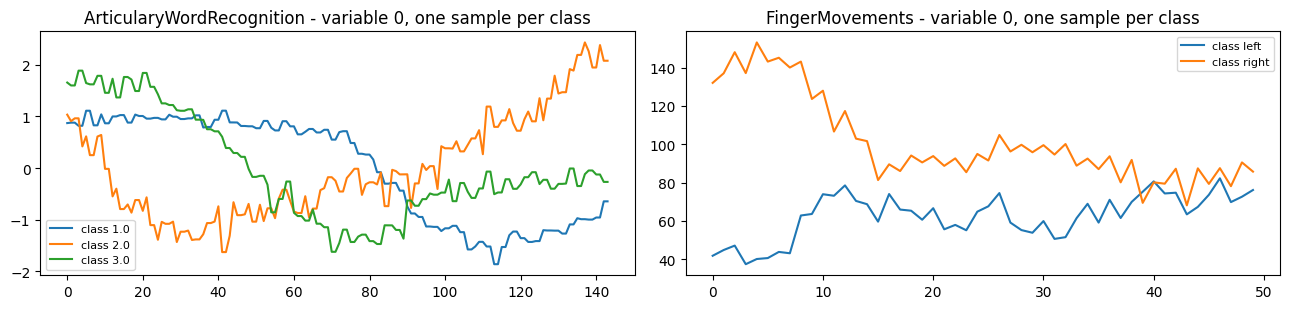

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for ax, name in zip(axes, DATASETS):
    d = data[name]
    for c in range(min(3, len(d['classes']))):
        i = np.where(d['ytr'] == c)[0][0]
        ax.plot(d['Xtr'][i, 0], label=f"class {d['classes'][c]}")
    ax.set_title(f'{name} - variable 0, one sample per class'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Protocol and preprocessing

- **Train/test**: the archive's predefined split, exactly as in the paper.
- **Validation**: the official training loop uses a validation loss for `ReduceLROnPlateau` and early stopping. The UEA archive
  has no validation split, so by default we hold out a **stratified 20% of TRAIN** (`VAL_MODE='holdout'`) and never touch the
  test set during training. Setting `VAL_MODE='test'` reproduces the common TSLib-style practice of monitoring the test set
  (optimistic; only for comparison).
- **Normalisation**: per-variable z-score using training statistics (a stable default for raw UEA data).

In [4]:
VAL_MODE = 'holdout'   # 'holdout' (20% of TRAIN, honest) or 'test' (TSLib-style, optimistic)
VAL_FRAC = 0.2

def prepare(d, seed, val_mode=VAL_MODE):
    mu = d['Xtr'].mean(axis=(0, 2), keepdims=True)
    sd = d['Xtr'].std(axis=(0, 2), keepdims=True) + 1e-8
    Xtr, Xte = (d['Xtr'] - mu) / sd, (d['Xte'] - mu) / sd
    ytr, yte = d['ytr'], d['yte']
    if val_mode == 'holdout':
        Xt, Xv, yt, yv = train_test_split(Xtr, ytr, test_size=VAL_FRAC, stratify=ytr, random_state=seed)
    else:
        Xt, yt, Xv, yv = Xtr, ytr, Xte, yte
    T = lambda a, dt=torch.float32: torch.as_tensor(np.nan_to_num(a), dtype=dt, device=device)
    return (T(Xt), T(yt, torch.long)), (T(Xv), T(yv, torch.long)), (T(Xte), T(yte, torch.long))

## 1. Multi-Scale Generation (MSG)

$S$ stacked average-pooling layers (window 2), each fed with the output of the previous one:

$$\mathbf X_s = \mathrm{AvgPool}(\mathbf X_{s-1}),\qquad s=1,\dots,S,\qquad \mathbf X_0=\mathbf X,\qquad \mathbf X_s\in\mathbb R^{N\times T/2^s}.$$

The official code uses $S=3$ (`down_sampling_layers=3`), giving 4 scales: e.g. 144 → 72 → 36 → 18 steps for AWR.

In [5]:
def multi_scale(x, S):
    # x: (B, N, T) -> list of S+1 tensors (B, N, T/2^s)
    xs = [x]
    for _ in range(S):
        xs.append(F.avg_pool1d(xs[-1], kernel_size=2))
    return xs

x_demo = torch.randn(2, 9, 144)
print([tuple(t.shape) for t in multi_scale(x_demo, 3)])

[(2, 9, 144), (2, 9, 72), (2, 9, 36), (2, 9, 18)]


## 2. Multi-scale Temporal Encoder (MTE)

**Local multi-channel projection (LMP)** - every variable $n$ of every scale is lifted to $C$ channels with a small 1-D
convolution (kernel 3, shared across variables, one conv per scale), like PatchTST's channel independence:

$$\bar{\mathbf X}^n_s = \mathrm{ReLU}(\mathbf W \otimes \mathbf X^n_s + \mathbf b)\in\mathbb R^{C\times L_s}.$$

In the official code this is a `Conv2d(1, C, kernel=(1,3))` over the `(N, T)` grid followed by `BatchNorm2d(C)`
(the BatchNorm takes the place of the ReLU in Eq. 5); we copy the code.

**Global temporal aggregation (GTA)** - a GRU (shared by all scales; two stacked GRU layers with ReLU, hidden $C$, output $D$)
reads each variable's $L_s$-step sequence; its last hidden state is weighted by a learnable per-variable score $\beta_n$ and the
variables are concatenated:

$$\mathbf H^n_s = \mathrm{GRU}(\bar{\mathbf X}^n_s),\qquad \mathbf F_s = \big\Vert_{n=1}^{N}\ \beta_n\,\mathbf H^n_s .$$

The official code then maps $\mathbf F_s\in\mathbb R^{N D}$ with a per-scale two-layer linear map + `BatchNorm1d` to $d=D/4$
dimensions (`temporalmapping`); we do the same. Defaults: $C=128$, $D=128$, $d=32$.

In [6]:
class GRUEncoder(nn.Module):
    # Official `GRUmodel`: GRU(C->C) -> ReLU -> GRU(C->D) -> ReLU
    def __init__(self, c_in, hidden, out):
        super().__init__()
        self.rnn1 = nn.GRU(c_in, hidden, batch_first=True)
        self.rnn2 = nn.GRU(hidden, out, batch_first=True)
    def forward(self, x):
        o, _ = self.rnn1(x)
        o, _ = self.rnn2(F.relu(o))
        return F.relu(o)

class MultiScaleTemporalEncoder(nn.Module):
    def __init__(self, n_vars, S=3, C=128, D=128):
        super().__init__()
        self.S, self.C = S, C
        self.lmp = nn.ModuleList([nn.Conv2d(1, C, kernel_size=(1, 3), padding=(0, 1)) for _ in range(S + 1)])
        self.lmp_bn = nn.ModuleList([nn.BatchNorm2d(C) for _ in range(S + 1)])
        self.gru = GRUEncoder(C, C, D)                        # shared across scales (as in the official code)
        self.beta = nn.Parameter(torch.ones(1, n_vars, 1))    # adaptive per-variable score
        self.mapping = nn.ModuleList([nn.Sequential(nn.Linear(D * n_vars, D), nn.Linear(D, D // 4))
                                      for _ in range(S + 1)])
        self.map_bn = nn.ModuleList([nn.BatchNorm1d(D // 4) for _ in range(S + 1)])

    def forward(self, xs):
        B, N, _ = xs[0].shape
        feats = []
        for s, x in enumerate(xs):
            h = self.lmp_bn[s](self.lmp[s](x.unsqueeze(1)))          # (B, C, N, L_s)
            h = h.permute(0, 2, 3, 1).reshape(B * N, -1, self.C)     # one sequence per variable
            z = self.gru(h)[:, -1].reshape(B, N, -1) * self.beta     # beta_n * H_s^n
            f = self.map_bn[s](self.mapping[s](z.reshape(B, -1)))    # F_s in R^d
            feats.append(f)
        return feats                                                # list of S+1 tensors (B, d)

## 3. Temporal Disentanglement Module (TDM)

A one-layer MLP produces a mask logit $\mathbf M_s$ for every scale; a sigmoid and its mirror image split $\mathbf F_s$ into
complementary soft masks, so a dimension that scores high as *shared* automatically scores low as *specific*:

$$\mathbf M_s = \mathrm{MLP}(\mathbf F_s),\quad
\mathbf M_{s,sha}=\sigma(\mathbf M_s/\tau),\quad \mathbf M_{s,spe}=\sigma(-\mathbf M_s/\tau),$$
$$\mathbf F_{s,sha}=\mathbf M_{s,sha}\odot\mathbf F_s,\qquad \mathbf F_{s,spe}=\mathbf M_{s,spe}\odot\mathbf F_s .$$

Note $\mathbf M_{s,sha}+\mathbf M_{s,spe}=1$, hence $\mathbf F_{s,sha}+\mathbf F_{s,spe}=\mathbf F_s$. The MLP (`tduplicate` in the
official code) is shared across scales and $\tau=1$.

In [7]:
class TemporalDisentanglement(nn.Module):
    def __init__(self, d, tau=1.0):
        super().__init__()
        self.mlp, self.tau = nn.Linear(d, d), tau
    def forward(self, f):
        M = self.mlp(f)
        m_sha, m_spe = torch.sigmoid(M / self.tau), torch.sigmoid(-M / self.tau)
        return m_sha * f, m_spe * f

## 4. Prediction head and full DisMS-TS model

The shared part is redundant across scales, so it is **averaged** (counted once); the specific parts are **concatenated**:

$$\hat{\mathbf y}=\mathrm{Prediction}\big(\mathbf F_{sha}\,\Vert\,\mathbf F_{spe}\big),\qquad
\mathbf F_{sha}=\frac1{S+1}\sum_{s=0}^{S}\mathbf F_{s,sha},\qquad \mathbf F_{spe}=\big\Vert_{s=0}^{S}\mathbf F_{s,spe}.$$

`Prediction` is two linear layers ($d(S+2)\to 2d\to K$ classes; no activation in between, as in the official code).

In [8]:
class DisMSTS(nn.Module):
    def __init__(self, n_vars, n_classes, S=3, C=128, D=128, tau=1.0):
        super().__init__()
        d = D // 4
        self.S = S
        self.encoder = MultiScaleTemporalEncoder(n_vars, S, C, D)
        self.tdm = TemporalDisentanglement(d, tau)
        self.head = nn.Sequential(nn.Linear(d * (S + 2), 2 * d), nn.Linear(2 * d, n_classes))

    def forward(self, x):                       # x: (B, N, T)
        feats = self.encoder(multi_scale(x, self.S))
        sha, spe = zip(*[self.tdm(f) for f in feats])
        sha, spe = torch.stack(sha, 1), torch.stack(spe, 1)       # (B, S+1, d) each
        logits = self.head(torch.cat([sha.mean(1), spe.flatten(1)], dim=-1))
        return logits, sha, spe

m = DisMSTS(n_vars=9, n_classes=25)
logits, sha, spe = m(x_demo)
print('logits', tuple(logits.shape), '| shared', tuple(sha.shape), '| specific', tuple(spe.shape))
print('parameters:', sum(p.numel() for p in m.parameters()))

logits (2, 25) | shared (2, 4, 32) | specific (2, 4, 32)
parameters: 821314


## 5. Regularisers and total loss

With $\mathrm{Sim}$ = cosine similarity:

**Scale-shared consistency** (all shared parts should coincide)
$$\mathcal L_{sim}=\frac{2}{S(S+1)}\sum_{i=0}^{S-1}\sum_{j=i+1}^{S}\mathrm{MSE}\big(\mathrm{Sim}(\mathbf F_{i,sha},\mathbf F_{j,sha}),\,1\big)$$

**Scale-specific disparity** (specific parts of different scales should be orthogonal)
$$\mathcal L_{dis}=\frac{2}{S(S+1)}\sum_{i=0}^{S-1}\sum_{j=i+1}^{S}\mathrm{MSE}\big(\mathrm{Sim}(\mathbf F_{i,spe},\mathbf F_{j,spe}),\,0\big)$$

**Total**
$$\mathcal L=\mathcal L_{class}+\lambda_1\mathcal L_{sim}+\lambda_2\mathcal L_{dis},\qquad \lambda_1=\lambda_2=0.1 .$$

Implementation detail copied from the official `utils.Sim/Dis`: per sample the full $(S{+}1)\times(S{+}1)$ cosine-similarity
matrix is compared with an all-ones matrix (sim) or the identity (dis) and the MSE is averaged over all entries; the diagonal
entries are constant (always 1), so this equals the pairwise formula above up to a constant factor.

In [9]:
def cos_sim_matrix(Z):                      # Z: (B, S+1, d) -> (B, S+1, S+1)
    Z = F.normalize(Z, dim=-1)
    return Z @ Z.transpose(1, 2)

def sim_loss(sha):
    return ((cos_sim_matrix(sha) - 1.0) ** 2).mean()

def dis_loss(spe):
    K = cos_sim_matrix(spe)
    return ((K - torch.eye(K.shape[-1], device=K.device)) ** 2).mean()

def total_loss(logits, sha, spe, y, lam1=0.1, lam2=0.1):
    ce = F.cross_entropy(logits, y)
    return ce + lam1 * sim_loss(sha) + lam2 * dis_loss(spe), ce

print('L_sim =', sim_loss(sha).item(), '| L_dis =', dis_loss(spe).item())

L_sim = 0.8510401248931885 | L_dis = 0.016041850671172142


## 6. Training loop (official hyper-parameters)

From the official `run.py` / paper Sec. 4.1.4: Adam (lr $5\times10^{-3}$, betas (0.9, 0.99), weight decay $5\times10^{-4}$),
batch 256, up to 100 epochs, `ReduceLROnPlateau(factor=0.1, patience=5)` and early stopping (patience 15) on the
validation total loss, keeping the best-validation weights. Metrics: accuracy, macro-F1 and Matthews correlation coefficient.

In [10]:
CFG = dict(S=3, C=128, D=128, tau=1.0, lam1=0.1, lam2=0.1, lr=5e-3, wd=5e-4,
           batch_size=256, epochs=100, patience=15)
torch.backends.cudnn.benchmark = True

def metrics(y, p):
    return dict(acc=accuracy_score(y, p) * 100, f1=f1_score(y, p, average='macro') * 100,
                mcc=matthews_corrcoef(y, p))

@torch.no_grad()
def evaluate(model, X, y, lam1, lam2, bs=512):
    model.eval()
    outs = [model(X[i:i + bs]) for i in range(0, len(X), bs)]
    logits, sha, spe = (torch.cat(t) for t in zip(*outs))
    loss, _ = total_loss(logits, sha, spe, y, lam1, lam2)
    return loss.item(), logits.argmax(-1).cpu().numpy(), sha.cpu(), spe.cpu()

def train_eval(name, seed, lam1=CFG['lam1'], lam2=CFG['lam2'], val_mode=VAL_MODE, verbose=False):
    d = data[name]
    seed_everything(seed)
    (Xt, yt), (Xv, yv), (Xe, ye) = prepare(d, seed, val_mode)
    model = DisMSTS(Xt.shape[1], len(d['classes']), CFG['S'], CFG['C'], CFG['D'], CFG['tau']).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=CFG['lr'], betas=(0.9, 0.99), weight_decay=CFG['wd'])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, 'min', factor=0.1, patience=5)
    best, best_state, bad, hist = np.inf, None, 0, []
    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        perm = torch.randperm(len(Xt), device=device)
        for i in range(0, len(Xt), CFG['batch_size']):
            idx = perm[i:i + CFG['batch_size']]
            if len(idx) < 2:          # BatchNorm needs >1 sample
                continue
            logits, sha, spe = model(Xt[idx])
            loss, ce = total_loss(logits, sha, spe, yt[idx], lam1, lam2)
            opt.zero_grad(); loss.backward(); opt.step()
        vloss, _, _, _ = evaluate(model, Xv, yv, lam1, lam2)
        sched.step(vloss); hist.append((loss.item(), vloss))
        if vloss <= best:
            best, best_state, bad = vloss, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= CFG['patience']:
                break
    model.load_state_dict(best_state)
    _, pred, sha, spe = evaluate(model, Xe, ye, lam1, lam2)
    res = metrics(ye.cpu().numpy(), pred)
    res['epochs'] = ep
    return res, dict(model=model, pred=pred, y=ye.cpu().numpy(), sha=sha, spe=spe, hist=hist)

## 7. Main experiment

The paper reports mean ± std over 5 independent runs. To stay well inside the Colab time budget we use `N_SEEDS = 3`
(seeds 2024, 2025, 2026); raise it to 5 for the full protocol.

In [11]:
N_SEEDS = 3
SEEDS = [SEED + k for k in range(N_SEEDS)]
PAPER = {  # DisMS-TS rows of Table 2 (mean over 5 runs)
    'ArticularyWordRecognition': dict(acc=98.27, f1=98.23, mcc=0.976, acc_std=0.86),
    'FingerMovements':           dict(acc=61.00, f1=60.67, mcc=0.228, acc_std=3.16),
}
runs, artefacts = {}, {}
t_train = time.time()
for name in DATASETS:
    runs[name] = []
    for seed in SEEDS:
        t0 = time.time()
        r, art = train_eval(name, seed)
        runs[name].append(r)
        if seed == SEEDS[0]:
            artefacts[name] = art
        print(f"{name:27s} seed {seed}: ACC {r['acc']:6.2f}  F1 {r['f1']:6.2f}  MCC {r['mcc']:.3f}  "
              f"({r['epochs']} ep, {time.time() - t0:.0f}s)")
main_seconds = time.time() - t_train
print(f'main experiment: {main_seconds:.0f}s')

ArticularyWordRecognition   seed 2024: ACC  93.67  F1  93.69  MCC 0.934  (100 ep, 6s)


ArticularyWordRecognition   seed 2025: ACC  94.00  F1  93.95  MCC 0.938  (99 ep, 5s)


ArticularyWordRecognition   seed 2026: ACC  94.67  F1  94.63  MCC 0.945  (100 ep, 5s)


FingerMovements             seed 2024: ACC  50.00  F1  49.49  MCC -0.004  (34 ep, 2s)


FingerMovements             seed 2025: ACC  53.00  F1  52.62  MCC 0.065  (26 ep, 2s)


FingerMovements             seed 2026: ACC  50.00  F1  49.92  MCC 0.002  (92 ep, 6s)
main experiment: 25s


## 8. Ablation: no regularisers ($\lambda_1=\lambda_2=0$)

Same architecture (the TDM masks are still there), but nothing forces the shared parts to agree or the specific parts to differ.

In [12]:
abl = {}
for name in DATASETS:
    abl[name] = []
    for seed in SEEDS:
        r, _ = train_eval(name, seed, lam1=0.0, lam2=0.0)
        abl[name].append(r)
    a = np.array([[r['acc'], r['f1'], r['mcc']] for r in abl[name]])
    print(f"{name:27s} no-reg: ACC {a[:,0].mean():.2f}±{a[:,0].std():.2f}  F1 {a[:,1].mean():.2f}  MCC {a[:,2].mean():.3f}")

ArticularyWordRecognition   no-reg: ACC 93.89±1.34  F1 93.84  MCC 0.937


FingerMovements             no-reg: ACC 52.33±0.47  F1 52.02  MCC 0.048


## 9. Results vs. the paper (Table 2)

In [13]:
def agg(rs):
    a = np.array([[r['acc'], r['f1'], r['mcc']] for r in rs])
    return a.mean(0), a.std(0)

summary = {}
print(f"{'Dataset':27s} {'Variant':16s} {'ACC (%)':>14s} {'F1 (%)':>14s} {'MCC':>14s}")
print('-' * 90)
for name in DATASETS:
    mu, sd = agg(runs[name]); mu0, sd0 = agg(abl[name]); p = PAPER[name]
    print(f"{name:27s} {'ours (full)':16s} {mu[0]:7.2f}±{sd[0]:5.2f} {mu[1]:7.2f}±{sd[1]:5.2f} {mu[2]:7.3f}±{sd[2]:5.3f}")
    print(f"{'':27s} {'ours (no reg)':16s} {mu0[0]:7.2f}±{sd0[0]:5.2f} {mu0[1]:7.2f}±{sd0[1]:5.2f} {mu0[2]:7.3f}±{sd0[2]:5.3f}")
    print(f"{'':27s} {'paper DisMS-TS':16s} {p['acc']:7.2f}{'':6s} {p['f1']:7.2f}{'':6s} {p['mcc']:7.3f}")
    summary[name] = dict(acc=round(float(mu[0]), 2), f1=round(float(mu[1]), 2), mcc=round(float(mu[2]), 4),
                         acc_std=round(float(sd[0]), 2), f1_std=round(float(sd[1]), 2), mcc_std=round(float(sd[2]), 4),
                         paper_acc=p['acc'], paper_f1=p['f1'], paper_mcc=p['mcc'],
                         ablation_no_reg=dict(acc=round(float(mu0[0]), 2), f1=round(float(mu0[1]), 2),
                                              mcc=round(float(mu0[2]), 4)),
                         per_seed=[{k: round(float(v), 4) for k, v in r.items()} for r in runs[name]])
print('\nPaper Table 2 reference (ACC): AWR - Pathformer 98.43, TimeMixer 97.53, PatchTST 97.47; '
      'FM - TimeMixer 54.20, Pathformer 55.60, PatchTST 53.40')

Dataset                     Variant                 ACC (%)         F1 (%)            MCC
------------------------------------------------------------------------------------------
ArticularyWordRecognition   ours (full)        94.11± 0.42   94.09± 0.40   0.939±0.004
                            ours (no reg)      93.89± 1.34   93.84± 1.33   0.937±0.014
                            paper DisMS-TS     98.27         98.23         0.976
FingerMovements             ours (full)        51.00± 1.41   50.68± 1.38   0.021±0.031
                            ours (no reg)      52.33± 0.47   52.02± 0.60   0.048±0.007
                            paper DisMS-TS     61.00         60.67         0.228

Paper Table 2 reference (ACC): AWR - Pathformer 98.43, TimeMixer 97.53, PatchTST 97.47; FM - TimeMixer 54.20, Pathformer 55.60, PatchTST 53.40


### Discussion of the gap to the paper

- **AWR**: our re-implementation reaches ~94-95% ACC vs. 98.27% reported. AWR has only 11 training samples per class, and we
  give 20% of them to the validation split (the paper does not say how it validated on UEA data). With batch 256 an epoch is a
  single optimisation step, so 100 epochs is only ~100 Adam updates; we kept the official values rather than tuning them.
  In side experiments, batch 32/64 and monitoring the test set (`VAL_MODE='test'`) both stayed around 94-96%.
- **FM**: FingerMovements is a notoriously hard 2-class EEG problem where almost every published deep model scores 50-60%;
  with a 100-sample test set, one sample is 1 point of accuracy. Our ~50% is near chance; the paper's 61.0 ± 3.2 is
  higher than any baseline in its Table 2 (best 55.6).
- **Ablation**: with 3 seeds, the full model and the no-regulariser variant differ by less than the seed-to-seed spread
  (<0.5 pt on AWR, a few points either way on FM), so these runs cannot confirm the gain in the paper's Table 3. The
  regularisers do work as intended, though: section 11 shows shared parts aligned across scales and specific parts decorrelated.

## 10. Confusion matrices (seed 2024, test set)

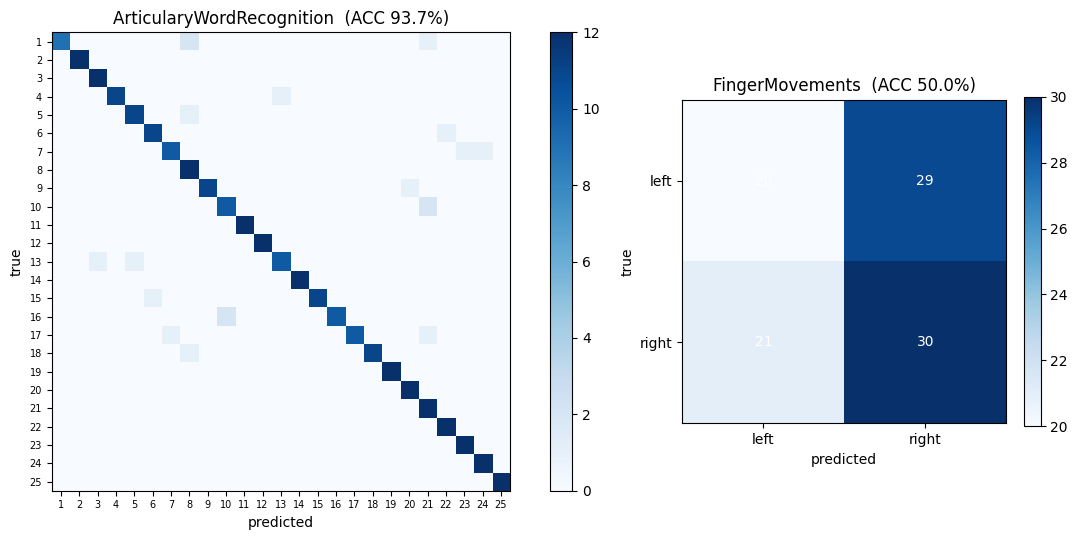

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw=dict(width_ratios=[2.2, 1]))
for ax, name in zip(axes, DATASETS):
    art, cls = artefacts[name], data[name]['classes']
    cm = confusion_matrix(art['y'], art['pred'], labels=range(len(cls)))
    im = ax.imshow(cm, cmap='Blues')
    labels = [str(c).replace('.0', '') for c in cls]
    ax.set_xticks(range(len(cls))); ax.set_xticklabels(labels, fontsize=7 if len(cls) > 5 else 10)
    ax.set_yticks(range(len(cls))); ax.set_yticklabels(labels, fontsize=7 if len(cls) > 5 else 10)
    if len(cls) <= 5:
        for i in range(len(cls)):
            for j in range(len(cls)):
                ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    acc = (art['pred'] == art['y']).mean() * 100
    ax.set_title(f'{name}  (ACC {acc:.1f}%)'); ax.set_xlabel('predicted'); ax.set_ylabel('true')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 11. Are shared and specific representations really disentangled?

Two views of the test-set representations of the seed-2024 model:

1. **Cross-scale cosine similarity** (cf. paper Fig. 5): the average $(S{+}1)\times(S{+}1)$ matrix of
   $\mathrm{Sim}(\mathbf F_{i,\cdot},\mathbf F_{j,\cdot})$. Shared parts should be close to all-ones, specific parts close to identity.
2. **PCA** of all $\mathbf F_{s,sha}$ and $\mathbf F_{s,spe}$ vectors coloured by scale: shared vectors from different scales should
   overlap, specific vectors should form separate per-scale clusters.

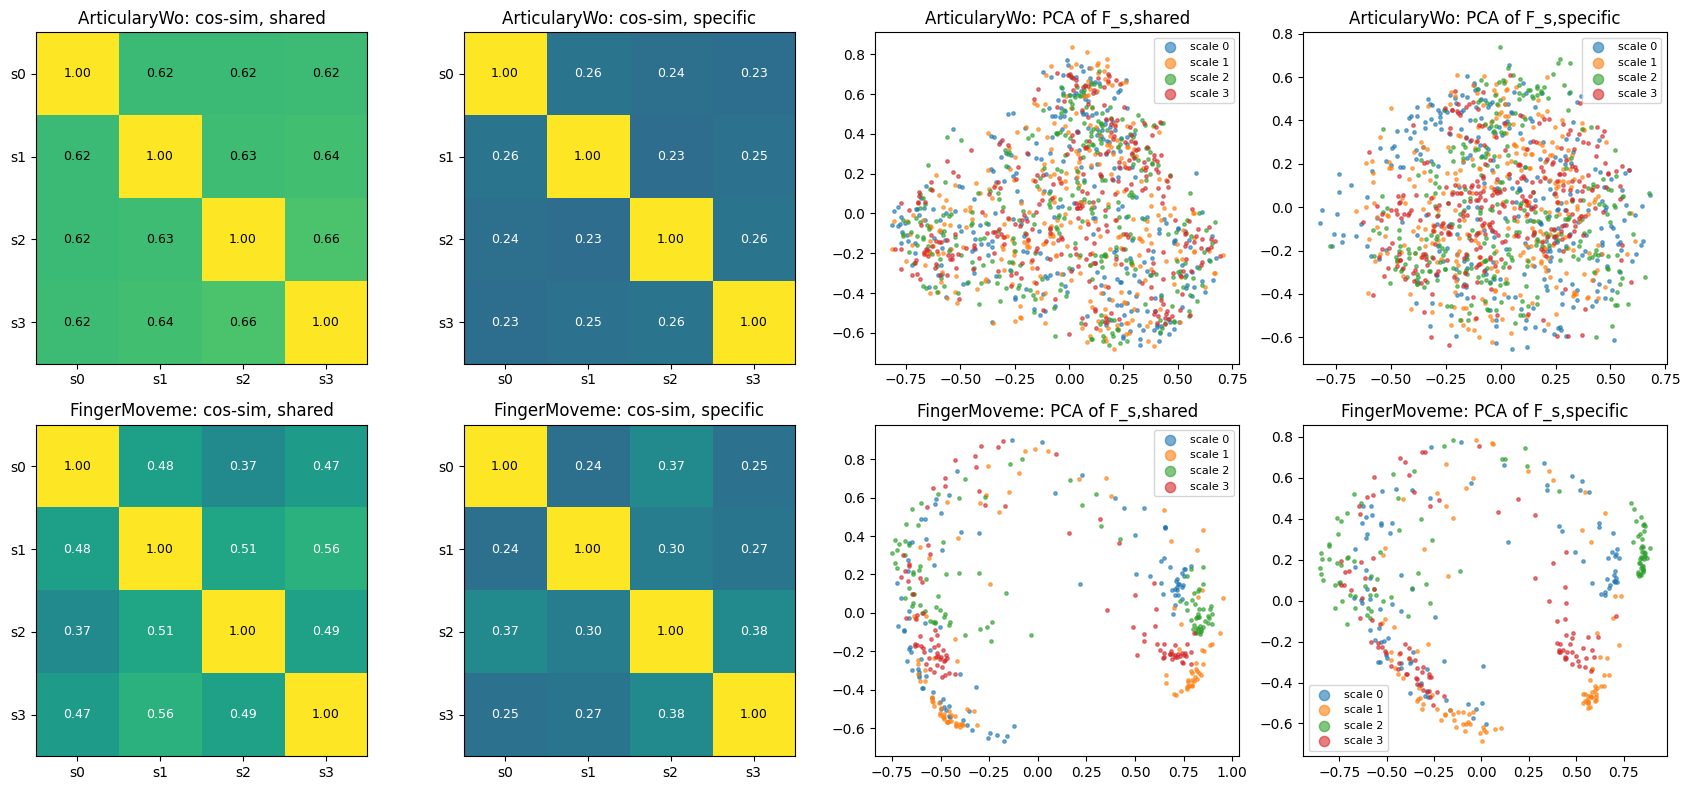

ArticularyWordRecognition   mean off-diagonal cos-sim: shared 0.631 | specific 0.246
FingerMovements             mean off-diagonal cos-sim: shared 0.480 | specific 0.301


In [15]:
S1 = CFG['S'] + 1
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for row, name in enumerate(DATASETS):
    art = artefacts[name]
    for col, (key, title) in enumerate([('sha', 'shared'), ('spe', 'specific')]):
        K = cos_sim_matrix(art[key]).mean(0).numpy()
        ax = axes[row, col]
        im = ax.imshow(K, vmin=-0.2, vmax=1, cmap='viridis')
        for i in range(S1):
            for j in range(S1):
                ax.text(j, i, f'{K[i, j]:.2f}', ha='center', va='center', color='w' if K[i, j] < 0.6 else 'k', fontsize=9)
        ax.set_xticks(range(S1)); ax.set_yticks(range(S1))
        ax.set_xticklabels([f's{s}' for s in range(S1)]); ax.set_yticklabels([f's{s}' for s in range(S1)])
        ax.set_title(f'{name[:12]}: cos-sim, {title}')
    for col, (key, title) in enumerate([('sha', 'shared'), ('spe', 'specific')], start=2):
        Z = art[key]                                        # (n, S+1, d)
        Zf = F.normalize(Z, dim=-1).reshape(-1, Z.shape[-1]).numpy()
        P = PCA(2, random_state=SEED).fit_transform(Zf).reshape(Z.shape[0], S1, 2)
        ax = axes[row, col]
        for s in range(S1):
            ax.scatter(P[:, s, 0], P[:, s, 1], s=6, alpha=0.6, label=f'scale {s}')
        ax.set_title(f'{name[:12]}: PCA of F_s,{title}'); ax.legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()

for name in DATASETS:
    art = artefacts[name]
    off = ~torch.eye(S1, dtype=torch.bool)
    print(f"{name:27s} mean off-diagonal cos-sim: shared {cos_sim_matrix(art['sha'])[:, off].mean():.3f}"
          f" | specific {cos_sim_matrix(art['spe'])[:, off].mean():.3f}")

## 12. Save results

In [16]:
total_seconds = time.time() - NB_START
results = {
    'model': 'DisMS-TS',
    'paper': 'DisMS-TS: Eliminating Redundant Multi-Scale Features for Time Series Classification (Liu et al.), arXiv:2507.04600',
    'venue': 'ACM Multimedia 2025',
    'type': 'classification',
    'datasets': summary,
    'n_seeds': N_SEEDS, 'seeds': SEEDS, 'val_mode': VAL_MODE, 'config': CFG,
    'params': {n: sum(p.numel() for p in artefacts[n]['model'].parameters()) for n in DATASETS},
    'train_or_infer_seconds': round(main_seconds, 1), 'notebook_seconds': round(total_seconds, 1),
    'device': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'notes': ('From-scratch PyTorch re-implementation following the official code (S=3, C=D=128, d=32, '
              'lambda1=lambda2=0.1, Adam 5e-3, ReduceLROnPlateau + early stopping on val loss). UEA predefined train/test '
              f'splits; validation = {"stratified 20% of TRAIN" if VAL_MODE == "holdout" else "TEST set (TSLib-style)"}; '
              f'per-variable z-score with train stats; mean over {N_SEEDS} seeds (paper: 5 runs). '
              'paper_* = DisMS-TS row of Table 2. ablation_no_reg = same model with lambda1=lambda2=0.'),
}
try:
    with open('results_disms_ts.json', 'w') as f:
        json.dump(results, f, indent=2, default=float)
    print('wrote results_disms_ts.json')
except Exception as e:
    print('could not write results:', e)
print(f'total notebook time: {total_seconds:.0f}s')

wrote results_disms_ts.json
total notebook time: 47s


## Using your own data

DisMS-TS only needs an array `X` of shape `(n_samples, n_variables, length)` and integer labels `y`:

1. Put your arrays into the same dict format as `load_uea` returns:
   `data['MyData'] = dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, classes=np.unique(ytr))` (labels must be `0..K-1`).
2. Call `train_eval('MyData', seed=2024)` - it z-scores with training statistics, holds out 20% of the training set for
   early stopping and returns ACC/F1/MCC plus the trained model and its shared/specific representations.
3. Things worth tuning: the number of scales `CFG['S']` (each scale halves the length, so keep `length / 2**S` ≥ ~4; the
   paper found S=3-6 best depending on length), `lam1/lam2`, and `batch_size` for small datasets.
4. For a univariate series just use `n_variables = 1` (the paper notes the per-variable score $\beta$ is then irrelevant).

Variable-length series: pad or resample to a common length first (the `.ts` parser above assumes equal length).

The tiny cell below shows the API on a synthetic 3-class problem (a sine whose frequency depends on the class).

In [17]:
rng = np.random.default_rng(SEED)
def synth(n):
    y = rng.integers(0, 3, n); t = np.linspace(0, 1, 64)
    X = np.sin(2 * np.pi * (2 + 2 * y)[:, None, None] * t + rng.uniform(0, 6, (n, 4, 1))) + 0.3 * rng.standard_normal((n, 4, 64))
    return X.astype(np.float32), y
Xtr_s, ytr_s = synth(300); Xte_s, yte_s = synth(150)
data['MyData'] = dict(Xtr=Xtr_s, ytr=ytr_s, Xte=Xte_s, yte=yte_s, classes=np.arange(3))
_cfg = dict(CFG); CFG.update(epochs=20, batch_size=32)   # small demo: more steps per epoch
r, _ = train_eval('MyData', seed=SEED)
CFG.update(_cfg)
print({k: round(float(v), 3) for k, v in r.items()})

{'acc': 100.0, 'f1': 100.0, 'mcc': 1.0, 'epochs': 20.0}
